Instructions
Please complete the following tasks as part of the Implementing Data Preprocessing Techniques in Machine Learning lab. All work must be implemented by you, and the results should be demonstrated to your lab instructor.
 1. Download the dataset from the link below and apply appropriate data preprocessing techniques to prepare it for machine learning models.
   https://drive.google.com/file/d/1xYswC3bRgW4y3ygyeCdrHVjTT5j_ZKdv/view?usp=sharing

2. Apply the following preprocessing steps:

■ Handle missing or invalid values

■ Scale numerical features

■ Encode categorical variables (if any)

■ Identify and handle outliers

3. For visualizing outliers, use box plots. Refer to the code below to create box plots for
numerical features:

4. To handle outliers, use the Interquartile Range (IQR) method as shown:
See Lab manual 2.8 section


1. Dataset has been downloaded from the provided deive link and uploaded to colab manually . The file path is  /content/sample_data/synthetic_employee_data.csv

**2.1 Handle missing or invalid values**

In [12]:
import pandas as pd
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

df = pd.read_csv('/content/sample_data/synthetic_employee_data.csv')

if 'ID' in df.columns:
    df = df.drop(columns=['ID'])

numeric_features = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = df.select_dtypes(include=['object', 'category']).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='passthrough'
)

X_processed = preprocessor.fit_transform(df)

all_feature_names = numeric_features + categorical_features
X_processed_df = pd.DataFrame(X_processed, columns=all_feature_names)

print("\n--- Fully Preprocessed Data (Missing Values Handled) ---")
print(X_processed_df)


--- Fully Preprocessed Data (Missing Values Handled) ---
       Age     Salary Years_at_Company Number_of_Projects Performance_Score  \
0    150.0  2000000.0             29.0                2.0               3.0   
1    200.0  1500000.0             37.0                7.0               3.0   
2      5.0  1200000.0              3.0                3.0               3.0   
3    200.0   23118.19             42.0                7.0               3.0   
4    150.0   20852.42             33.0                2.0               5.0   
..     ...        ...              ...                ...               ...   
995   37.0   36742.62             10.0                4.0               1.0   
996   62.0   20084.58             12.0                4.0               1.0   
997   48.0    15535.8             11.0                2.0               3.0   
998   33.0   19190.08              8.0                4.0               4.0   
999   47.0   35254.49             13.0                3.0               2

**2.2 Scale numerical features**

In [11]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

df = pd.read_csv('/content/sample_data/synthetic_employee_data.csv')

if 'ID' in df.columns:
    df = df.drop(columns=['ID'])

numeric_features = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features)
    ]
)

X_processed = preprocessor.fit_transform(df)

X_processed_df = pd.DataFrame(X_processed, columns=numeric_features)

print("\n--- Fully Preprocessed Data (Numerical Features) ---")
print(X_processed_df)


--- Fully Preprocessed Data (Numerical Features) ---
           Age     Salary  Years_at_Company  Number_of_Projects  \
0     7.159504  22.616194          4.576128           -0.992393   
1    10.436045  16.878551          6.522381            1.481169   
2    -2.342465  13.435965         -1.749195           -0.497681   
3    10.436045  -0.069090          7.738789            1.481169   
4     7.159504  -0.095090          5.549254           -0.992393   
..         ...        ...               ...                 ...   
995  -0.245478   0.087254         -0.046224           -0.002968   
996   1.392792  -0.103901          0.440340           -0.002968   
997   0.475361  -0.156100          0.197058           -0.992393   
998  -0.507602  -0.114166         -0.532787           -0.002968   
999   0.409830   0.070178          0.683621           -0.497681   

     Performance_Score  Is_Manager  Works_Remotely  
0             0.008119   -0.510915       -0.649981  
1             0.008119   -0.510915 

**2.3 Encode categorical variables **

In [13]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

df = pd.read_csv('/content/sample_data/synthetic_employee_data.csv')

if 'ID' in df.columns:
    df = df.drop(columns=['ID'])

categorical_features = df.select_dtypes(include=['object', 'category']).columns.tolist()

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', categorical_transformer, categorical_features)
    ]
)

X_processed = preprocessor.fit_transform(df)

ohe_feature_names = preprocessor.named_transformers_['cat']['onehot'].get_feature_names_out(categorical_features)
X_processed_df = pd.DataFrame(X_processed.toarray() if hasattr(X_processed, "toarray") else X_processed, columns=ohe_feature_names)

print("\n--- Fully Preprocessed Data (Categorical Features Encoded) ---")
print(X_processed_df)


--- Fully Preprocessed Data (Categorical Features Encoded) ---
     Employee_ID_E00001  Employee_ID_E00002  Employee_ID_E00003  \
0                   1.0                 0.0                 0.0   
1                   0.0                 1.0                 0.0   
2                   0.0                 0.0                 1.0   
3                   0.0                 0.0                 0.0   
4                   0.0                 0.0                 0.0   
..                  ...                 ...                 ...   
995                 0.0                 0.0                 0.0   
996                 0.0                 0.0                 0.0   
997                 0.0                 0.0                 0.0   
998                 0.0                 0.0                 0.0   
999                 0.0                 0.0                 0.0   

     Employee_ID_E00004  Employee_ID_E00005  Employee_ID_E00006  \
0                   0.0                 0.0                 0.0 

**2.4 Identify and handle outliers**

In [14]:
import pandas as pd
import numpy as np

df = pd.read_csv('/content/sample_data/synthetic_employee_data.csv')

if 'ID' in df.columns:
    df = df.drop(columns=['ID'])

numeric_features = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

for col in numeric_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df[col] = np.where(df[col] < lower_bound, lower_bound, df[col])
    df[col] = np.where(df[col] > upper_bound, upper_bound, df[col])

print("\n--- Outliers Handled (Capped using IQR) ---")
print(df)


--- Outliers Handled (Capped using IQR) ---
    Employee_ID  Employee_Name   Age      Salary  Years_at_Company  \
0        E00001    Alex Miller  72.0  53323.2775              20.5   
1        E00002     Alex Smith  72.0  53323.2775              20.5   
2        E00003    Jane Garcia   8.0  53323.2775               3.0   
3        E00004    Emily Brown  72.0  23118.1900              20.5   
4        E00005     Mike Jones  72.0  20852.4200              20.5   
..          ...            ...   ...         ...               ...   
995      E00996  Katie Johnson  37.0  36742.6200               NaN   
996      E00997     Alex Jones  62.0  20084.5800              12.0   
997      E00998    John Garcia  48.0  15535.8000              11.0   
998      E00999  Mike Williams  33.0  19190.0800               8.0   
999      E01000  Mike Williams  47.0  35254.4900              13.0   

     Number_of_Projects  Performance_Score  Is_Manager  Works_Remotely  \
0                   2.0                3

3. For visualizing outliers, use box plots. Refer to the code below to create box plots for numerical features:
**bold text**

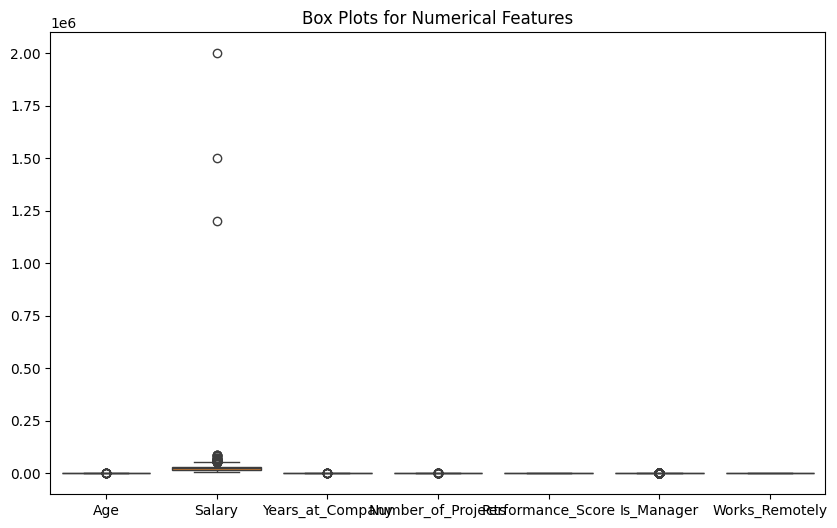

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/sample_data/synthetic_employee_data.csv')

if 'ID' in df.columns:
    df = df.drop(columns=['ID'])

numeric_features = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

plt.figure(figsize=(10, 6))
sns.boxplot(data=df[numeric_features])
plt.title("Box Plots for Numerical Features")
plt.show()

**4. To handle outliers, use the Interquartile Range (IQR)**

In [16]:
import pandas as pd
import numpy as np

df = pd.read_csv('/content/sample_data/synthetic_employee_data.csv')

if 'ID' in df.columns:
    df = df.drop(columns=['ID'])

numeric_features = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

for col in numeric_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df[col] = np.where(df[col] < lower_bound, lower_bound, df[col])
    df[col] = np.where(df[col] > upper_bound, upper_bound, df[col])

print("\n--- Fully Preprocessed Data (Outliers Handled) ---")
print(df)


--- Fully Preprocessed Data (Outliers Handled) ---
    Employee_ID  Employee_Name   Age      Salary  Years_at_Company  \
0        E00001    Alex Miller  72.0  53323.2775              20.5   
1        E00002     Alex Smith  72.0  53323.2775              20.5   
2        E00003    Jane Garcia   8.0  53323.2775               3.0   
3        E00004    Emily Brown  72.0  23118.1900              20.5   
4        E00005     Mike Jones  72.0  20852.4200              20.5   
..          ...            ...   ...         ...               ...   
995      E00996  Katie Johnson  37.0  36742.6200               NaN   
996      E00997     Alex Jones  62.0  20084.5800              12.0   
997      E00998    John Garcia  48.0  15535.8000              11.0   
998      E00999  Mike Williams  33.0  19190.0800               8.0   
999      E01000  Mike Williams  47.0  35254.4900              13.0   

     Number_of_Projects  Performance_Score  Is_Manager  Works_Remotely  \
0                   2.0          